# Task 1 — Exploratory Data Analysis: Titanic Passengers
**CodeNova AI/ML Internship · Batch 01**

**Dataset:** Titanic passenger records (public, `seaborn-data`, 891 rows × 15 columns).
**Question driving the analysis:** *Which passenger characteristics were associated with survival, and how trustworthy is the data?*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(name): plt.savefig(FIG / f"{name}.png"); plt.show()
df_raw = pd.read_csv("data/titanic.csv")
df_raw.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Dataset ingestion & profiling

In [2]:
print("Shape:", df_raw.shape)
display(df_raw.dtypes.to_frame("dtype").join(df_raw.nunique().rename("n_unique")))

Shape: (891, 15)


,dtype,n_unique
survived,int64,2
pclass,int64,3
sex,object,2
age,float64,88
sibsp,int64,7
parch,int64,7
fare,float64,248
embarked,object,3
class,object,3
who,object,3


In [3]:
miss = df_raw.isna().sum().to_frame("missing"); miss["pct"] = (miss.missing/len(df_raw)*100).round(1)
display(miss[miss.missing>0].sort_values("missing", ascending=False))
print("Exact duplicate rows:", df_raw.duplicated().sum())
display(df_raw.describe().T.round(2))

,missing,pct
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


Exact duplicate rows: 107


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


**Profile takeaways**
- `deck` is ~77% missing, `age` ~20%, `embarked`/`embark_town` only 2 rows.
- `class`/`pclass`, `sex`/`who`/`adult_male`, `embarked`/`embark_town` and `survived`/`alive` are **redundant encodings** of the same facts — one of each pair is dropped below to avoid double counting.
- `fare` is strongly right-skewed (mean far above median) → outlier handling matters.

## 2. Data cleaning

### 2a. Duplicates — detect, test, then decide
Titanic has no passenger-id column, so "duplicate" rows can only be rows that match on *every* attribute. We quantify them and test whether removing them changes any conclusion before deciding.

In [4]:
dups = df_raw.duplicated(keep=False)
print("Rows involved in exact duplication:", dups.sum(), "| surplus copies:", df_raw.duplicated().sum())
print("Share of duplicated rows that are 3rd-class males:", round(((df_raw[dups].pclass==3)&(df_raw[dups].sex=="male")).mean(),2))
dedup = df_raw.drop_duplicates()
sens = pd.DataFrame({"all 891 rows": [df_raw.survived.mean(), df_raw[df_raw.sex=="female"].survived.mean(), df_raw[df_raw.pclass==1].survived.mean(), df_raw[df_raw.pclass==3].survived.mean()],
                     "after dedup": [dedup.survived.mean(), dedup[dedup.sex=="female"].survived.mean(), dedup[dedup.pclass==1].survived.mean(), dedup[dedup.pclass==3].survived.mean()]},
                    index=["overall survival","female survival","1st-class survival","3rd-class survival"]).round(3)
display(sens)

Rows involved in exact duplication: 160 | surplus copies: 107
Share of duplicated rows that are 3rd-class males: 0.62


,all 891 rows,after dedup
overall survival,0.384,0.412
female survival,0.742,0.741
1st-class survival,0.630,0.631
3rd-class survival,0.242,0.257


**Decision: keep them.** The duplicated rows are concentrated in low-information groups (single, low-fare, 3rd-class passengers with identical age/fare/port), exactly where coincidental identical records are expected among 891 real people. Dropping them would delete genuine passengers and bias the sample towards unusual passengers. The sensitivity table shows headline rates move only slightly either way. `drop_duplicates()` is kept as a one-line switch (`REMOVE_DUPS`) for anyone who prefers the strict approach.

In [5]:
REMOVE_DUPS = False
df = (df_raw.drop_duplicates() if REMOVE_DUPS else df_raw).copy()
print(f"Working dataset: {len(df)} rows")

Working dataset: 891 rows


### 2b. Missing values — decisions & justification
| Column | Missing | Decision | Justification |
|---|---|---|---|
| `deck` | ~77% | **Drop** | With >75% missing any imputation would be mostly invented data. |
| `age` | ~20% | **Impute by median of (`pclass`,`sex`) group** | Age differs by class (see below) so a group median is lower-variance than a global one, and the median is robust to the right-skewed age distribution. A missing-flag column keeps the information that the value was imputed. |
| `embarked`, `embark_town` | 2 | **Fill with mode** | Only 0.2% of rows; the mode (Southampton) is the least-distorting choice. |
Redundant columns (`alive`, `class`, `who`, `adult_male`, `embark_town`) are dropped.

In [6]:
print("Median age by class & sex (justifies group imputation):")
display(df.groupby(["pclass","sex"]).age.median().unstack().round(1))
print("Age std overall: %.2f | mean within-group std: %.2f" % (df.age.std(), df.groupby(["pclass","sex"]).age.std().mean()))

Median age by class & sex (justifies group imputation):


sex,female,male
pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


Age std overall: 14.53 | mean within-group std: 13.55


In [7]:
df["age_was_missing"] = df.age.isna().astype(int)
df["age"] = df.age.fillna(df.groupby(["pclass","sex"]).age.transform("median"))
df["embarked"] = df.embarked.fillna(df.embarked.mode()[0])
df = df.drop(columns=["deck","alive","class","who","adult_male","embark_town"])
df["family_size"] = df.sibsp + df.parch + 1
print("Remaining missing values:", int(df.isna().sum().sum()))
df.head()

Remaining missing values: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone,age_was_missing,family_size
0,0,3,male,22.0,1,0,7.2500,S,False,0,2
1,1,1,female,38.0,1,0,71.2833,C,False,0,2
2,1,3,female,26.0,0,0,7.9250,S,True,0,1
3,1,1,female,35.0,1,0,53.1000,S,False,0,2
4,0,3,male,35.0,0,0,8.0500,S,True,0,1


### 2c. Outlier detection (IQR rule, 1.5×IQR)
Outliers are **flagged, not deleted**: very high fares are real (first-class suites), so removing them would erase genuine signal. For modelling or correlation we use a `log1p` transform to tame the skew.

In [8]:
def iqr_outliers(s):
    q1,q3 = s.quantile([.25,.75]); iqr=q3-q1
    lo,hi = q1-1.5*iqr, q3+1.5*iqr
    return ((s<lo)|(s>hi)).sum(), lo, hi
rows=[]
for c in ["age","fare","sibsp","parch","family_size"]:
    n,lo,hi = iqr_outliers(df[c]); rows.append([c,n,round(n/len(df)*100,1),round(lo,1),round(hi,1)])
display(pd.DataFrame(rows,columns=["feature","n_outliers","pct","lower_fence","upper_fence"]))
print("Fare skewness: raw=%.2f  log1p=%.2f" % (df.fare.skew(), np.log1p(df.fare).skew()))
df["log_fare"] = np.log1p(df.fare)

,feature,n_outliers,pct,lower_fence,upper_fence
0,age,33,3.7,-0.2,57.8
1,fare,116,13.0,-26.7,65.6
2,sibsp,46,5.2,-1.5,2.5
3,parch,213,23.9,0.0,0.0
4,family_size,91,10.2,-0.5,3.5


Fare skewness: raw=4.79  log1p=0.39


## 3. Visualisations & narrative

### 3.1 Feature distributions

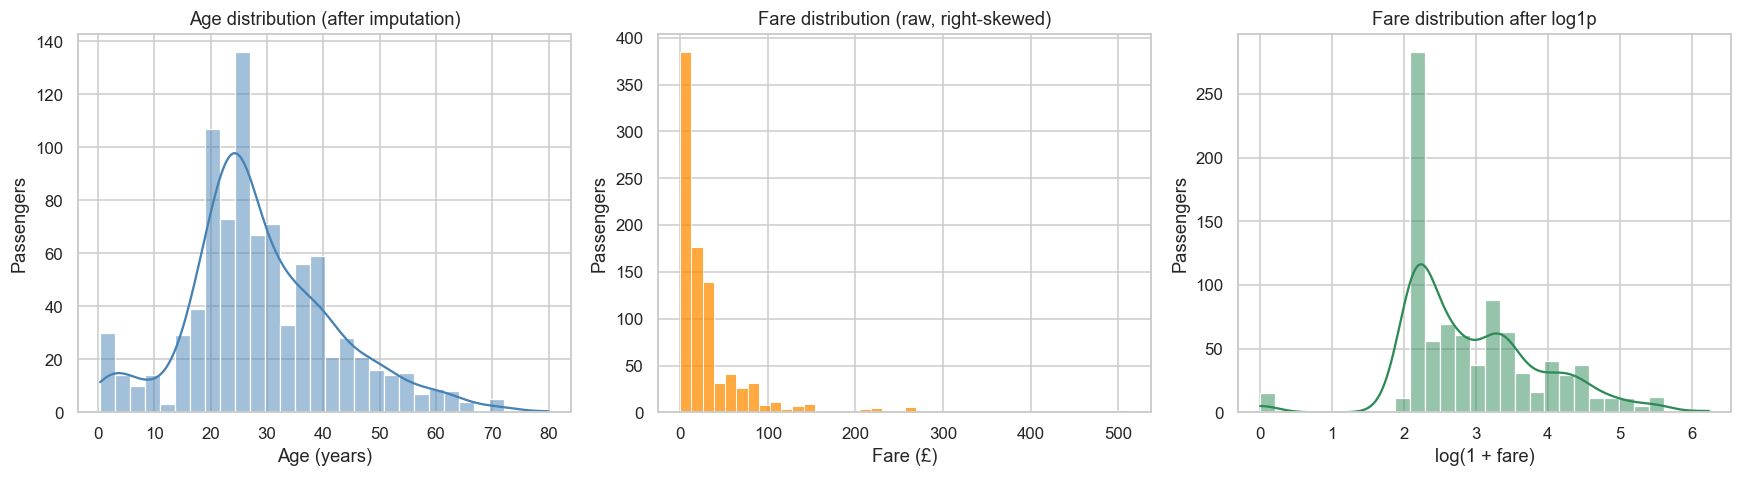

In [9]:
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
sns.histplot(df.age, bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set(title="Age distribution (after imputation)", xlabel="Age (years)", ylabel="Passengers")
sns.histplot(df.fare, bins=40, ax=ax[1], color="darkorange")
ax[1].set(title="Fare distribution (raw, right-skewed)", xlabel="Fare (£)", ylabel="Passengers")
sns.histplot(df.log_fare, bins=30, kde=True, ax=ax[2], color="seagreen")
ax[2].set(title="Fare distribution after log1p", xlabel="log(1 + fare)", ylabel="Passengers")
plt.tight_layout(); save("01_distributions")

In [10]:
print(df[["age","fare"]].agg(["mean","median","skew"]).round(2))

          age   fare
mean    29.11  32.20
median  26.00  14.45
skew     0.53   4.79


**Takeaway.** Most passengers were young adults (median age 26, mean 29.1, mild right skew of 0.53; the small spike near the group medians is a side-effect of imputation, which we accept and flag). Fare is heavily right-skewed (median £14.45 vs mean £32.20; skewness 4.79 → 0.39 after `log1p`), so linear or distance-based models should use log-fare and the mean fare is a misleading summary.

### 3.2 Survival by categorical features

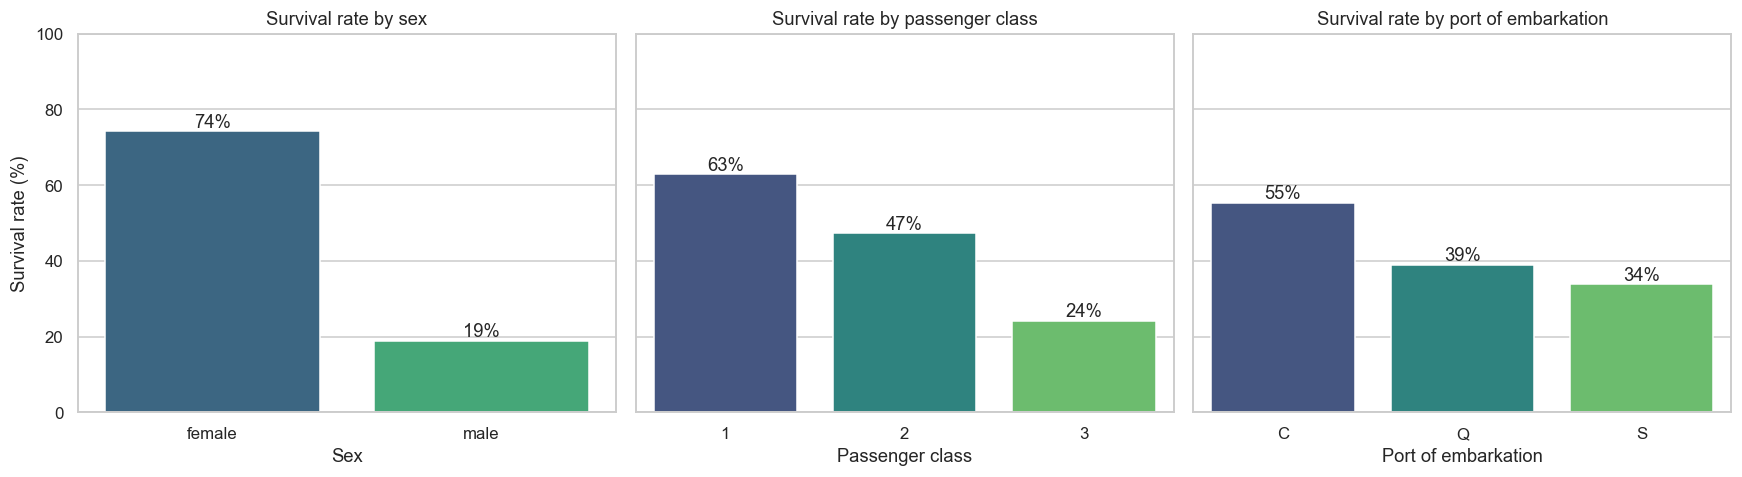

mean               count          
pclass      1      2      3     1    2    3
sex                                        
female  0.968  0.921  0.500    94   76  144
male    0.369  0.157  0.135   122  108  347

In [11]:
fig, ax = plt.subplots(1,3, figsize=(16,4.5), sharey=True)
for a,(c,t) in zip(ax,[("sex","Sex"),("pclass","Passenger class"),("embarked","Port of embarkation")]):
    rate = df.groupby(c).survived.mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=a, hue=rate.index.astype(str), legend=False, palette="viridis")
    for i,v in enumerate(rate.values): a.text(i, v+1, f"{v:.0f}%", ha="center")
    a.set(title=f"Survival rate by {t.lower()}", xlabel=t, ylabel="Survival rate (%)", ylim=(0,100))
plt.tight_layout(); save("02_survival_categorical")
display(df.groupby(["sex","pclass"]).survived.agg(["mean","count"]).round(3).unstack())

**Takeaway.** Sex is by far the strongest separator: about 74% of women survived versus about 19% of men. Class is a clear second: 63% survival in 1st class vs 24% in 3rd. The two compound — 1st/2nd-class women survived at 97% and 92% while 3rd-class men survived at only 13.5%. Practically, `sex` and `pclass` together separate survivors from non-survivors very strongly, so they belong in any downstream model. "Women and children first" and cabin location relative to lifeboats are plausible mechanisms, but the data alone cannot prove causation.

### 3.3 Boxplots — outliers and group differences

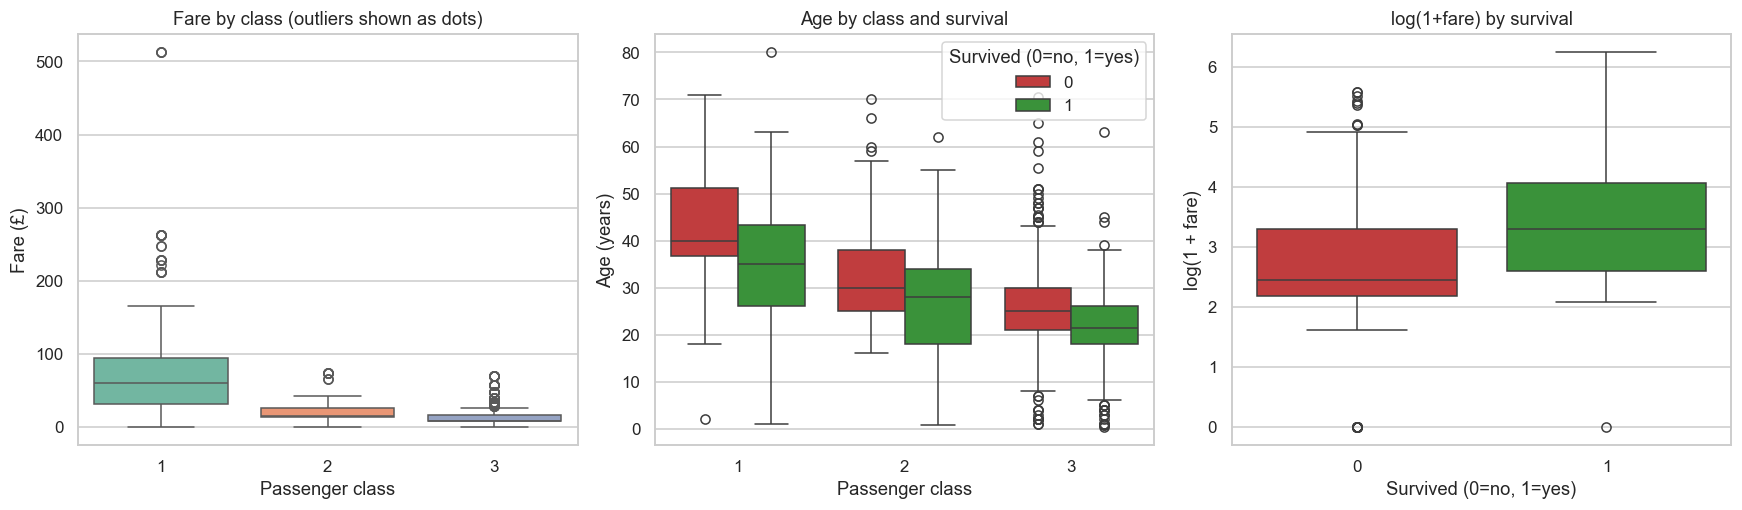

        median fare
pclass             
1             60.29
2             14.25
3              8.05


In [12]:
fig, ax = plt.subplots(1,3, figsize=(16,4.8))
sns.boxplot(data=df, x="pclass", y="fare", ax=ax[0], hue="pclass", legend=False, palette="Set2")
ax[0].set(title="Fare by class (outliers shown as dots)", xlabel="Passenger class", ylabel="Fare (£)")
sns.boxplot(data=df, x="pclass", y="age", hue="survived", ax=ax[1], palette=["#d62728","#2ca02c"])
ax[1].set(title="Age by class and survival", xlabel="Passenger class", ylabel="Age (years)")
ax[1].legend(title="Survived (0=no, 1=yes)")
sns.boxplot(data=df, x="survived", y="log_fare", ax=ax[2], hue="survived", legend=False, palette=["#d62728","#2ca02c"])
ax[2].set(title="log(1+fare) by survival", xlabel="Survived (0=no, 1=yes)", ylabel="log(1 + fare)")
plt.tight_layout(); save("03_boxplots")
print(df.groupby("pclass").fare.median().round(2).to_frame("median fare"))

**Takeaway.** The fare outliers are overwhelmingly 1st class (104 of 116 flagged by the IQR rule, and every fare above £200) — real luxury tickets up to £512, not errors, which justifies flagging rather than removing them. Median age rises with class (37 in 1st, 29 in 2nd, 24 in 3rd), and survivors paid more (median fare £26 vs £10.50), consistent with the class effect above. `parch` shows 213 'outliers' only because its IQR is 0 (most passengers travel without parents/children) — the rule is not meaningful for it.

### 3.4 Correlation heatmap

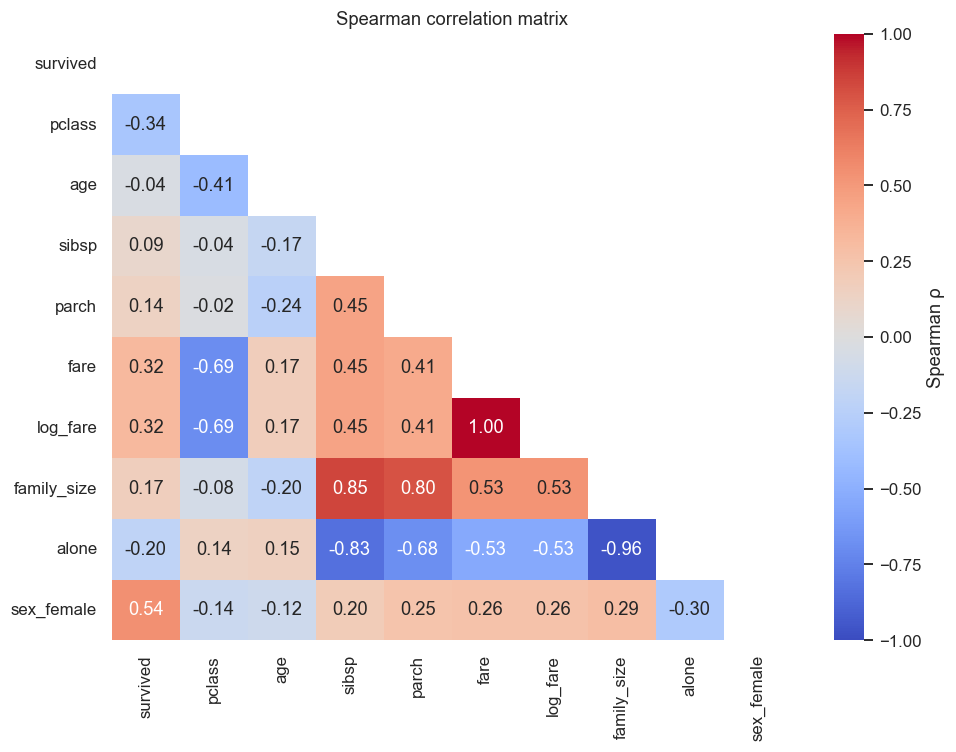

,ρ with survived
sex_female,0.543
pclass,-0.340
fare,0.324
log_fare,0.324
alone,-0.203
family_size,0.165
parch,0.138
sibsp,0.089
age,-0.039


In [13]:
num = df[["survived","pclass","age","sibsp","parch","fare","log_fare","family_size","alone"]].assign(alone=lambda d: d.alone.astype(int), sex_female=(df.sex=="female").astype(int))
corr = num.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9,7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"label":"Spearman ρ"})
plt.grid(False); plt.title("Spearman correlation matrix"); plt.tight_layout(); save("04_correlation_heatmap")
display(corr.survived.drop("survived").sort_values(key=abs, ascending=False).round(3).to_frame("ρ with survived"))

**Takeaway.** Spearman (rank) correlation is used because fare is skewed. Survival correlates most with being female (ρ = +0.54) and passenger class (ρ = −0.34, with `fare`/`log_fare` mirroring it at +0.32). `fare` and `pclass` are strongly negatively correlated with each other (ρ = −0.69), and `sibsp`/`parch`/`family_size` are mutually correlated by construction — so if building a model, keep only one feature from each cluster to limit multicollinearity.

### 3.5 Pairwise scatter plots

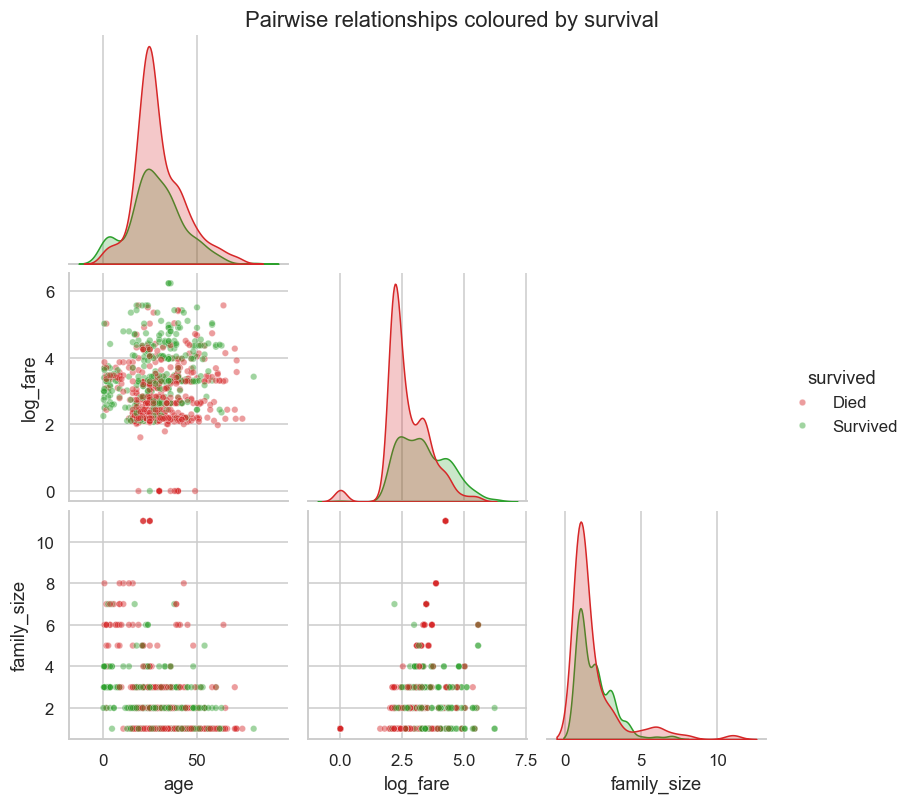

In [14]:
sub = df[["age","log_fare","family_size","survived"]].copy()
sub["survived"] = sub.survived.map({0:"Died",1:"Survived"})
g = sns.pairplot(sub, hue="survived", palette={"Died":"#d62728","Survived":"#2ca02c"}, corner=True, plot_kws={"alpha":.45,"s":18}, height=2.4)
g.figure.suptitle("Pairwise relationships coloured by survival", y=1.01)
g.savefig(FIG/"05_pairplot.png"); plt.show()

**Takeaway.** The pairplot shows no clean linear separation between survivors and non-survivors in any single pair of these features — consistent with the weak linear correlations above and with the fact that the strongest drivers (sex, class) are categorical. `family_size` shows a non-linear pattern (next chart) that a linear correlation understates.

family_size,1,2,3,4,5,6,7,8,11
mean,0.304,0.553,0.578,0.724,0.2,0.136,0.333,0.0,0.0
count,537.000,161.000,102.000,29.000,15.0,22.000,12.000,6.0,7.0


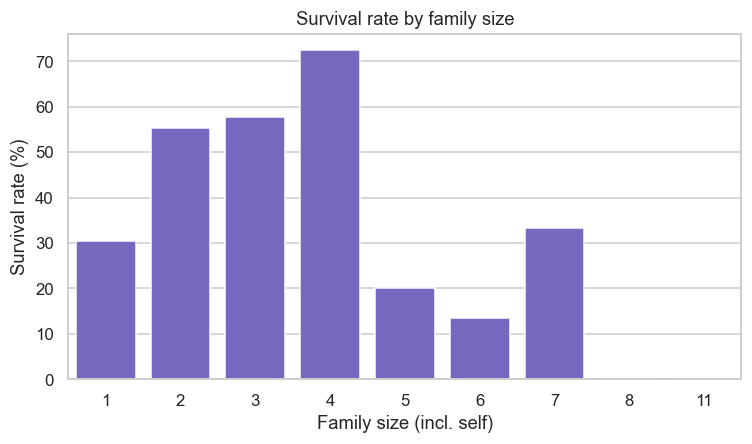

In [15]:
fs = df.groupby("family_size").survived.agg(["mean","count"]).round(3); display(fs.T)
plt.figure(figsize=(7,4.2)); sns.barplot(x=fs.index, y=fs["mean"]*100, color="slateblue")
plt.title("Survival rate by family size"); plt.xlabel("Family size (incl. self)"); plt.ylabel("Survival rate (%)")
plt.tight_layout(); save("06_family_size")

**Takeaway.** Survival peaks at family sizes 2–4 (55%, 58%, 72%), is 30% for solo travellers, and collapses for 5+ (0–33%): a non-monotonic relationship worth encoding as a feature bucket rather than as a raw number. Large-family groups are small (≤ 22 passengers per size), so these rates are noisy.

## 4. Key conclusions
1. **Sex and class dominate** survival; their interaction (1st-class women 97% vs 3rd-class men 13.5%) spans an 83-point gap in survival rate.
2. **Data quality:** `deck` too sparse to use; `age` imputed with class×sex medians (flagged); 107 exact-duplicate rows kept after a sensitivity check; fares skewed — use `log1p`.
3. **Outliers are real**, not errors — keep them, transform instead of delete.
4. **Family size is non-linear**; bucket it for downstream models.
5. **Caveat:** associations are observational; Titanic is a single historical event with survivorship in the records themselves, so conclusions do not generalise to other settings.